# Confronto fra metriche di complessità dei prodotti

Correlazioni (Spearman) fra le misure di complessità dei prodotti in un anno:
- estese: Q, CQ, Δ della fitness estesa e Q dell'ECI esteso
- classiche: complessità della fitness (Tacchella et al.) e PCI (Hidalgo–Hausmann)
- numero di input $N_1$
- metriche esterne, se presenti in `EXTERNAL` (es. PCI dell'Atlas of Economic Complexity): vengono unite per codice prodotto

Metriche da `results/econometria/metriche/` (via `src/storage.py`). Figure in `plots/econometria/confronto_metriche_prodotti/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = next(p for p in [Path().resolve(), *Path().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.storage import load_metrics_long
import matplotlib.pyplot as plt
from src.plotting import (set_style, figsize, save_fig, two_part_legend, common_ylim,
                          SINGLE, HALF, PALETTE, RES_MARKER, SEQ_CMAP, SYMBOLS)

set_style()

# famiglie di colore: fitness = blu, ECI = arancio; estesa = scura, classica = chiara
METRIC_COLOR = {"extended_fitness": "#0072B2", "fitness": "#56B4E9", "extended_eci": "#D55E00", "eci": "#E69F00"}
METRIC_LABEL = {"extended_fitness": "Extended Fitness", "fitness": "Fitness", "extended_eci": "Extended ECI", "eci": "ECI"}

## Configurazione

In [2]:
YEAR = 2002
RESOLUTIONS = [4, 6]
COLUMNS = {                                   # (metrica, variabile) -> etichetta
    ("extended_fitness", "Q"): r"$Q$ Ext. Fitness", ("extended_fitness", "CQ"): r"$QC$ fit. est.",
    ("extended_fitness", "Delta"): r"$\Delta$ fit. est.", ("extended_eci", "Q"): r"$Q$ Ext. ECI",
    ("fitness", "Q"): r"$Q$ fitness", ("eci", "PCI"): "PCI",
}
# metriche esterne: nome -> (file .csv/.parquet, colonna codice prodotto, colonna valore, risoluzione)
EXTERNAL = {}

SAVE_FIGS = True
FIG_DIR = ROOT / "plots" / "econometria" / "confronto_metriche_prodotti" 

## Dati

In [3]:
def table(res):
    r = load_metrics_long(res, "product", years=[YEAR]).pivot_table(index="product", columns=["metric", "variable"], values="value")
    T = pd.DataFrame({lab: r[key] for key, lab in COLUMNS.items()})
    C = pd.read_parquet(ROOT / "data" / "HS02_all_years" / f"{res}_digits" / "alligned" / "binarized" / "C" / f"C_{res}_digits_HS02.parquet")
    T[r"$N_1$"] = C.sum(axis=0).reindex(T.index)
    for name, (path, pcol, vcol, r_ext) in EXTERNAL.items():
        if r_ext != res:
            continue
        e = pd.read_parquet(path) if str(path).endswith(".parquet") else pd.read_csv(path, dtype={pcol: str})
        T[name] = e.set_index(pcol)[vcol].reindex(T.index)
    return T

tables = {res: table(res) for res in RESOLUTIONS}
for res, T in tables.items():
    print(f"{res} digits: {len(T)} prodotti, colonne: {list(T.columns)}")

4 digits: 1205 prodotti, colonne: ['$Q$ Ext. Fitness', '$QC$ fit. est.', '$\\Delta$ fit. est.', '$Q$ Ext. ECI', '$Q$ fitness', 'PCI', '$N_1$']
6 digits: 5079 prodotti, colonne: ['$Q$ Ext. Fitness', '$QC$ fit. est.', '$\\Delta$ fit. est.', '$Q$ Ext. ECI', '$Q$ fitness', 'PCI', '$N_1$']


## Matrice di correlazione (Spearman)

4 digits


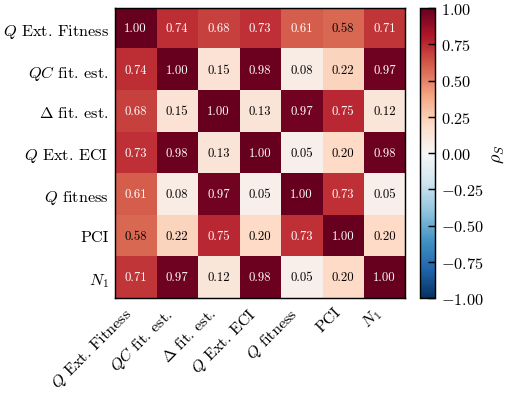

6 digits


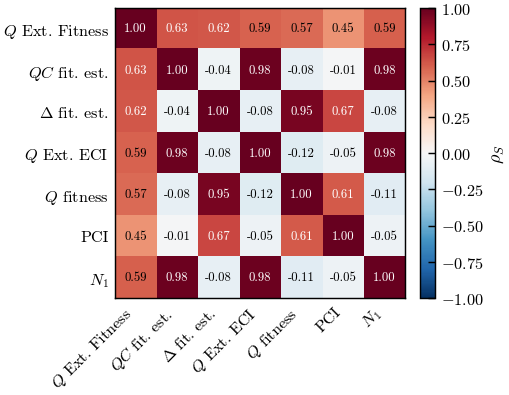

In [4]:
for res, T in tables.items():
    R = T.corr(method="spearman")
    fig, ax = plt.subplots(figsize=figsize(0.7, 0.8))
    im = ax.imshow(R.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(R))); ax.set_xticklabels(R.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(R))); ax.set_yticklabels(R.columns)
    ax.tick_params(which="both", length=0)
    for i in range(len(R)):
        for j in range(len(R)):
            v = R.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(v) > 0.6 else "k")
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label(r"$\rho_S$")
    fig.tight_layout()
    if SAVE_FIGS:
        save_fig(fig, FIG_DIR / f"correlazioni_{res}_digits_{YEAR}")
    print(f"{res} digits"); plt.show()

## Metriche estese vs classiche (per prodotto)

4 digits: $Q$ fitness vs $Q$ Ext. Fitness


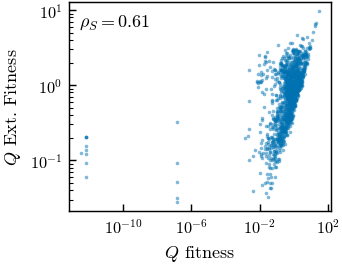

4 digits: PCI vs $Q$ Ext. ECI


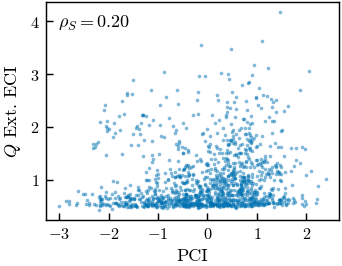

6 digits: $Q$ fitness vs $Q$ Ext. Fitness


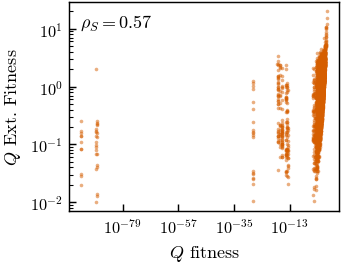

6 digits: PCI vs $Q$ Ext. ECI


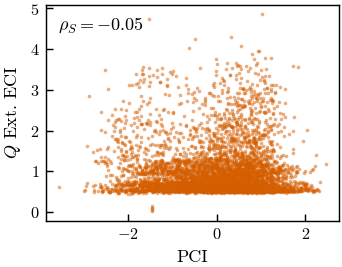

In [5]:
PAIRS = [(r"$Q$ fitness", r"$Q$ Ext. Fitness", "log"), ("PCI", r"$Q$ Ext. ECI", "lin")]

for res, T in tables.items():
    for xcol, ycol, scale in PAIRS:
        d = T[[xcol, ycol]].dropna()
        if scale == "log":
            d = d[(d > 0).all(axis=1)]
        fig, ax = plt.subplots(figsize=figsize(*HALF))
        ax.scatter(d[xcol], d[ycol], s=4, color=PALETTE[res], alpha=0.5, lw=0)
        if scale == "log":
            ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlabel(xcol); ax.set_ylabel(ycol)
        rho = d[xcol].corr(d[ycol], method="spearman")
        ax.text(0.04, 0.95, rf"$\rho_S = {rho:.2f}$", transform=ax.transAxes, va="top")
        fig.tight_layout()
        if SAVE_FIGS:
            tag = "fitness" if "fitness" in xcol else "eci"
            save_fig(fig, FIG_DIR / f"scatter_{tag}_{res}_digits_{YEAR}")
        print(f"{res} digits: {xcol} vs {ycol}"); plt.show()